In [22]:
import copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from collections import Counter
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [23]:
mean, std = [0.449], [0.226]

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_ds = ImageFolder("./img/dataset/train", transform=train_tf)
val_ds   = ImageFolder("./img/dataset/val",   transform=eval_tf)
test_ds  = ImageFolder("./img/dataset/test",  transform=eval_tf)

BATCH_SIZE = 16
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False)

classes = train_ds.classes
for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    print(name, {classes[k]: v for k, v in sorted(Counter(ds.targets).items())})

images, labels = next(iter(train_loader))
print(images.shape)

train {'donuts': 94, 'fleischschnacka': 94, 'frite': 89, 'hamburger': 92}
val {'donuts': 23, 'fleischschnacka': 18, 'frite': 17, 'hamburger': 18}
test {'donuts': 19, 'fleischschnacka': 19, 'frite': 19, 'hamburger': 18}
torch.Size([16, 1, 224, 224])


In [24]:
device = "cuda" if torch.cuda.is_available() else "cpu"
num_classes = len(classes)

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

w = model.conv1.weight.data.sum(dim=1, keepdim=True)
model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
model.conv1.weight.data = w

for p in model.parameters():
    p.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
print("device :", device, "| classes :", classes)

device : cpu | classes : ['donuts', 'fleischschnacka', 'frite', 'hamburger']


In [25]:
def run_epoch(loader, train=True):
    model.train(train)
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history = {"tr_loss": [], "va_loss": [], "tr_acc": [], "va_acc": []}
best = {"acc": 0.0, "state": None}

def fit(epochs):
    for epoch in range(epochs):
        tr_loss, tr_acc = run_epoch(train_loader, True)
        va_loss, va_acc = run_epoch(val_loader, False)
        for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc]):
            history[k].append(v)
        if va_acc > best["acc"]:
            best["acc"], best["state"] = va_acc, copy.deepcopy(model.state_dict())
        print(f"Epoch {len(history['tr_loss'])}: train {tr_loss:.3f}/{tr_acc:.2%} | val {va_loss:.3f}/{va_acc:.2%}")

fit(60)

Epoch 1: train 1.233/49.32% | val 0.918/61.84%
Epoch 2: train 0.845/73.98% | val 0.581/85.53%
Epoch 3: train 0.649/85.91% | val 0.466/90.79%
Epoch 4: train 0.581/82.66% | val 0.461/88.16%
Epoch 5: train 0.535/84.28% | val 0.327/94.74%
Epoch 6: train 0.432/87.53% | val 0.308/94.74%
Epoch 7: train 0.445/85.37% | val 0.276/90.79%
Epoch 8: train 0.441/86.45% | val 0.237/96.05%
Epoch 9: train 0.390/89.16% | val 0.241/93.42%
Epoch 10: train 0.350/91.60% | val 0.230/97.37%
Epoch 11: train 0.353/90.51% | val 0.278/93.42%
Epoch 12: train 0.350/89.97% | val 0.219/96.05%
Epoch 13: train 0.350/89.70% | val 0.220/92.11%
Epoch 14: train 0.300/90.51% | val 0.204/97.37%
Epoch 15: train 0.299/91.60% | val 0.174/96.05%
Epoch 16: train 0.281/93.50% | val 0.178/97.37%
Epoch 17: train 0.314/89.16% | val 0.193/96.05%
Epoch 18: train 0.263/93.22% | val 0.150/96.05%
Epoch 19: train 0.265/92.41% | val 0.189/94.74%
Epoch 20: train 0.272/92.41% | val 0.174/96.05%
Epoch 21: train 0.246/93.22% | val 0.144/97.37%
E

## 4. Courbes

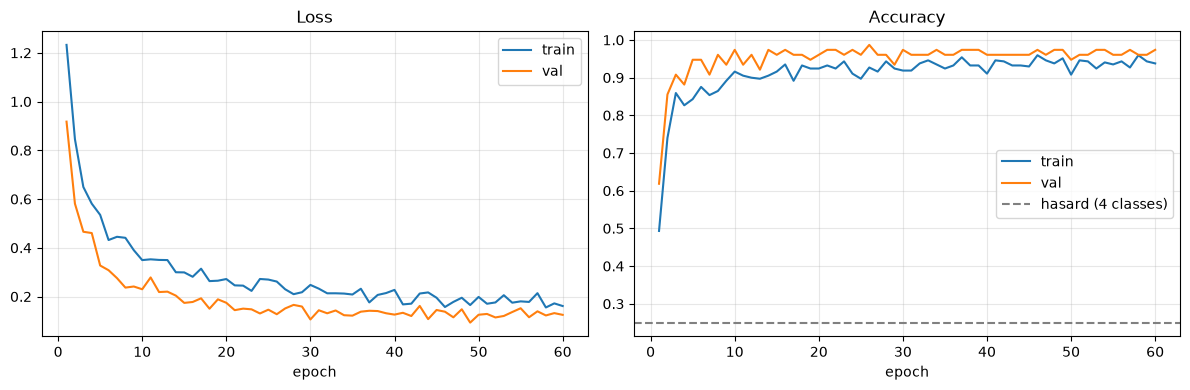

In [26]:
def plot_history():
    epochs = range(1, len(history["tr_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(epochs, history["tr_loss"], label="train")
    ax[0].plot(epochs, history["va_loss"], label="val")
    ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[1].plot(epochs, history["tr_acc"], label="train")
    ax[1].plot(epochs, history["va_acc"], label="val")
    ax[1].axhline(1/num_classes, color="gray", linestyle="--", label=f"hasard ({num_classes} classes)")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

plot_history()

## 5. (Optionnel) Fine-tuning : on dégèle `layer4` avec un petit learning rate
À lancer seulement si l'accuracy val plafonne après l'étape 3.

Epoch 61: train 0.230/90.51% | val 0.085/94.74%
Epoch 62: train 0.095/95.93% | val 0.070/98.68%
Epoch 63: train 0.117/96.48% | val 0.278/92.11%
Epoch 64: train 0.070/98.10% | val 0.262/93.42%
Epoch 65: train 0.065/98.10% | val 0.247/96.05%
Epoch 66: train 0.062/98.37% | val 0.103/94.74%
Epoch 67: train 0.068/97.83% | val 0.141/96.05%
Epoch 68: train 0.047/98.10% | val 0.157/94.74%
Epoch 69: train 0.044/98.64% | val 0.150/97.37%
Epoch 70: train 0.026/99.19% | val 0.112/96.05%


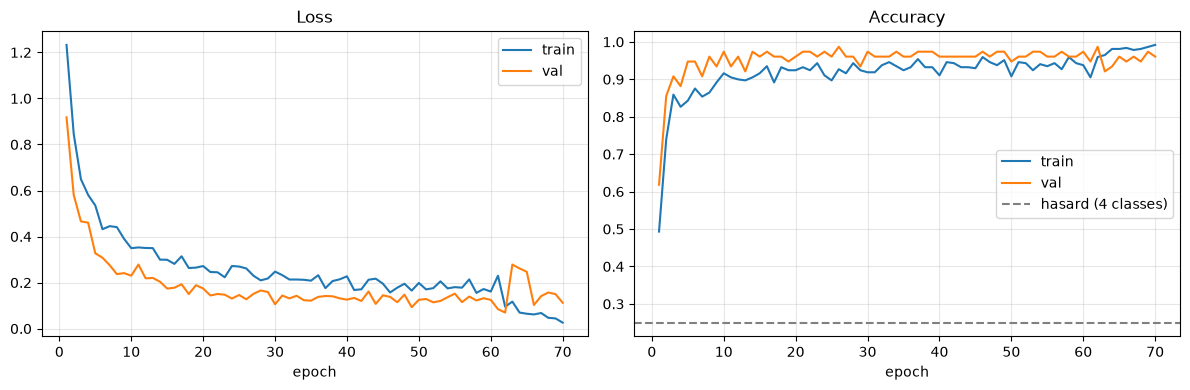

In [27]:
for p in model.layer4.parameters():
    p.requires_grad = True

optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(),     "lr": 1e-3},
])
fit(10)
plot_history()

## 6. Évaluation sur le test (avec les meilleurs poids)

Meilleure val accuracy : 98.68%
                 precision    recall  f1-score   support

         donuts      0.944     0.895     0.919        19
fleischschnacka      0.938     0.789     0.857        19
          frite      0.857     0.947     0.900        19
      hamburger      0.900     1.000     0.947        18

       accuracy                          0.907        75
      macro avg      0.910     0.908     0.906        75
   weighted avg      0.910     0.907     0.905        75



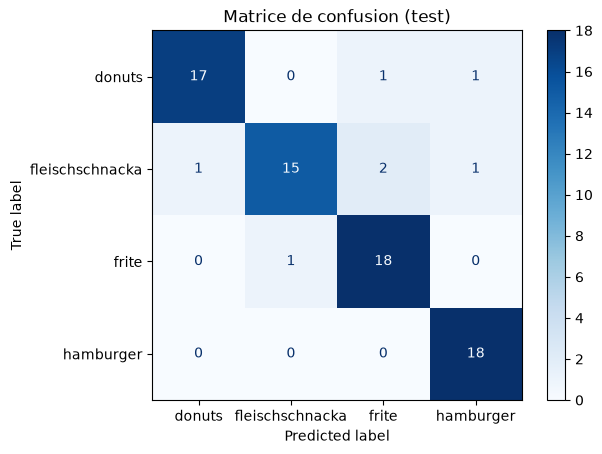

In [28]:
model.load_state_dict(best["state"])
print(f"Meilleure val accuracy : {best['acc']:.2%}")

def get_preds(loader):
    model.eval()
    preds, trues, probs = [], [], []
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(device))
            probs += torch.softmax(out, 1).cpu().tolist()
            preds += out.argmax(1).cpu().tolist()
            trues += y.tolist()
    return np.array(trues), np.array(preds), np.array(probs)

y_true, y_pred, y_prob = get_preds(test_loader)
print(classification_report(y_true, y_pred, target_names=classes, digits=3, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=classes).plot(cmap="Blues")
plt.title("Matrice de confusion (test)")
plt.show()

## 7. Images : vraie classe vs prédiction (vert = correct, rouge = erreur)

12 images au hasard :


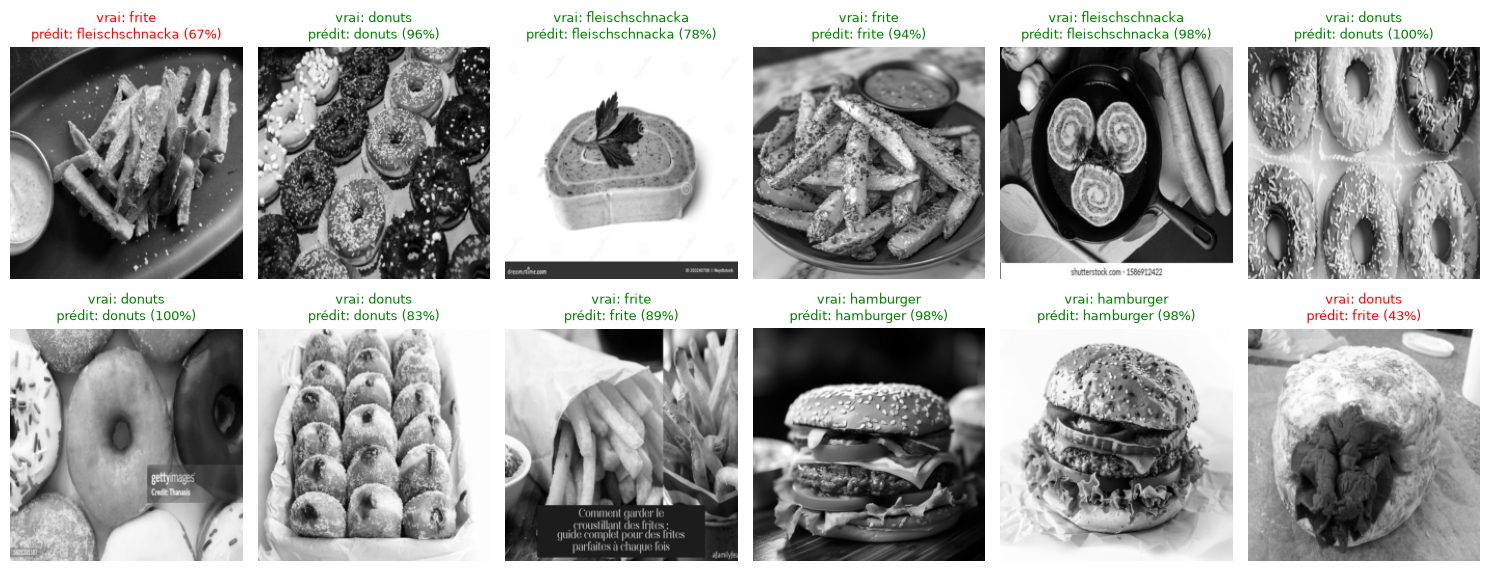

7 erreurs sur 75


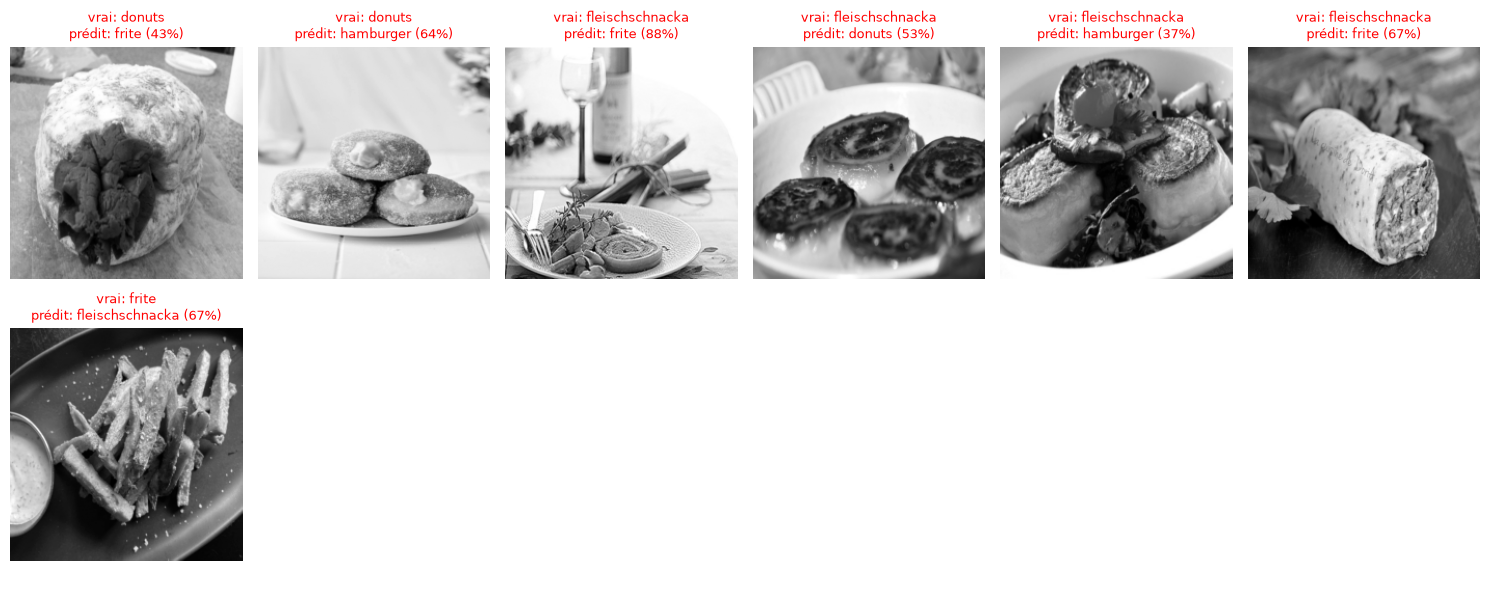

In [29]:
def show_predictions(ds, indices, cols=6):
    rows = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 3))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, i in zip(axes, indices):
        img, _ = ds[i]
        img = img * std[0] + mean[0]          # dé-normalise
        ok = y_true[i] == y_pred[i]
        ax.imshow(img.squeeze().clamp(0, 1), cmap="gray")
        ax.set_title(
            f"vrai: {classes[y_true[i]]}\nprédit: {classes[y_pred[i]]} ({y_prob[i][y_pred[i]]:.0%})",
            fontsize=9, color="green" if ok else "red",
        )
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
print("12 images au hasard :")
show_predictions(test_ds, rng.choice(len(test_ds), size=min(12, len(test_ds)), replace=False))

wrong = np.where(y_true != y_pred)[0]
print(f"{len(wrong)} erreurs sur {len(y_true)}")
if len(wrong):
    show_predictions(test_ds, wrong[:12])